In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df=pd.read_csv('bank.csv')

In [3]:
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343,yes,no,unknown,5,may,1042,1,-1,0,unknown,yes
1,56,admin.,married,secondary,no,45,no,no,unknown,5,may,1467,1,-1,0,unknown,yes
2,41,technician,married,secondary,no,1270,yes,no,unknown,5,may,1389,1,-1,0,unknown,yes
3,55,services,married,secondary,no,2476,yes,no,unknown,5,may,579,1,-1,0,unknown,yes
4,54,admin.,married,tertiary,no,184,no,no,unknown,5,may,673,2,-1,0,unknown,yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11157,33,blue-collar,single,primary,no,1,yes,no,cellular,20,apr,257,1,-1,0,unknown,no
11158,39,services,married,secondary,no,733,no,no,unknown,16,jun,83,4,-1,0,unknown,no
11159,32,technician,single,secondary,no,29,no,no,cellular,19,aug,156,2,-1,0,unknown,no
11160,43,technician,married,secondary,no,0,no,yes,cellular,8,may,9,2,172,5,failure,no


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11162 entries, 0 to 11161
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        11162 non-null  int64
 1   job        11162 non-null  str  
 2   marital    11162 non-null  str  
 3   education  11162 non-null  str  
 4   default    11162 non-null  str  
 5   balance    11162 non-null  int64
 6   housing    11162 non-null  str  
 7   loan       11162 non-null  str  
 8   contact    11162 non-null  str  
 9   day        11162 non-null  int64
 10  month      11162 non-null  str  
 11  duration   11162 non-null  int64
 12  campaign   11162 non-null  int64
 13  pdays      11162 non-null  int64
 14  previous   11162 non-null  int64
 15  poutcome   11162 non-null  str  
 16  deposit    11162 non-null  str  
dtypes: int64(7), str(10)
memory usage: 2.0 MB


In [5]:
df.isna().sum()

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
deposit      0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
cols=[x for x in df.columns if df[x].dtype=='str']
df[cols[9]].value_counts()

deposit
no     5873
yes    5289
Name: count, dtype: int64

In [8]:
cols_encoded_one_hot=['job','marital','education','contact','month','poutcome']
cols_encoded_label=['default','housing','loan','deposit']
standard_sclaer_cols=[x for x in df.columns if df[x].dtype=='int64']

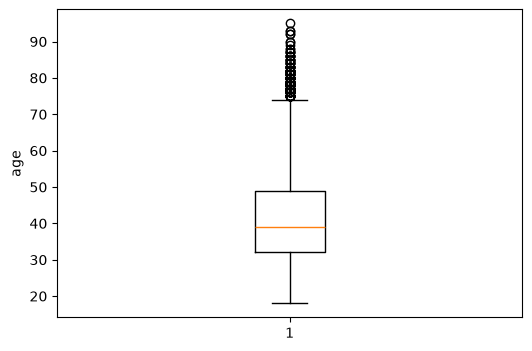

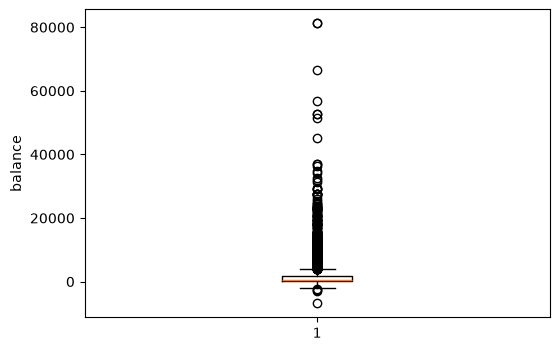

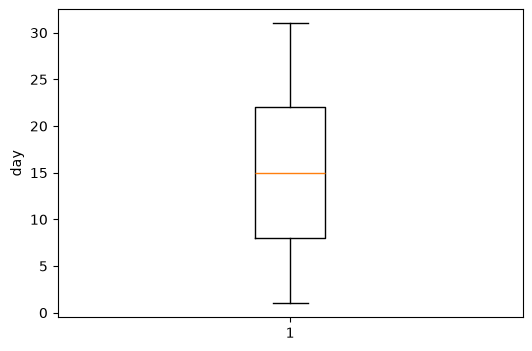

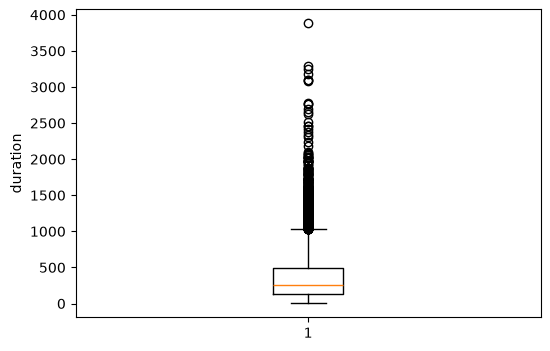

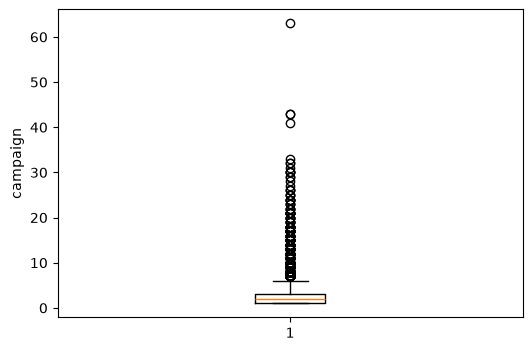

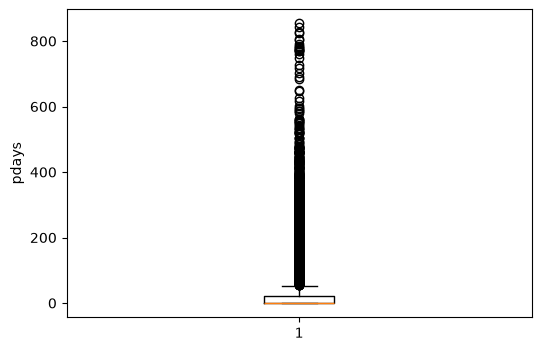

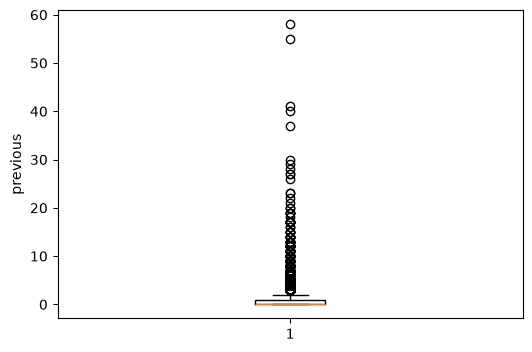

In [9]:
for i in df.columns:
    if df[i].dtype=='int64':
        plt.figure(figsize=(6,4))
        plt.boxplot(df[i])
        plt.ylabel(i)

<Axes: >

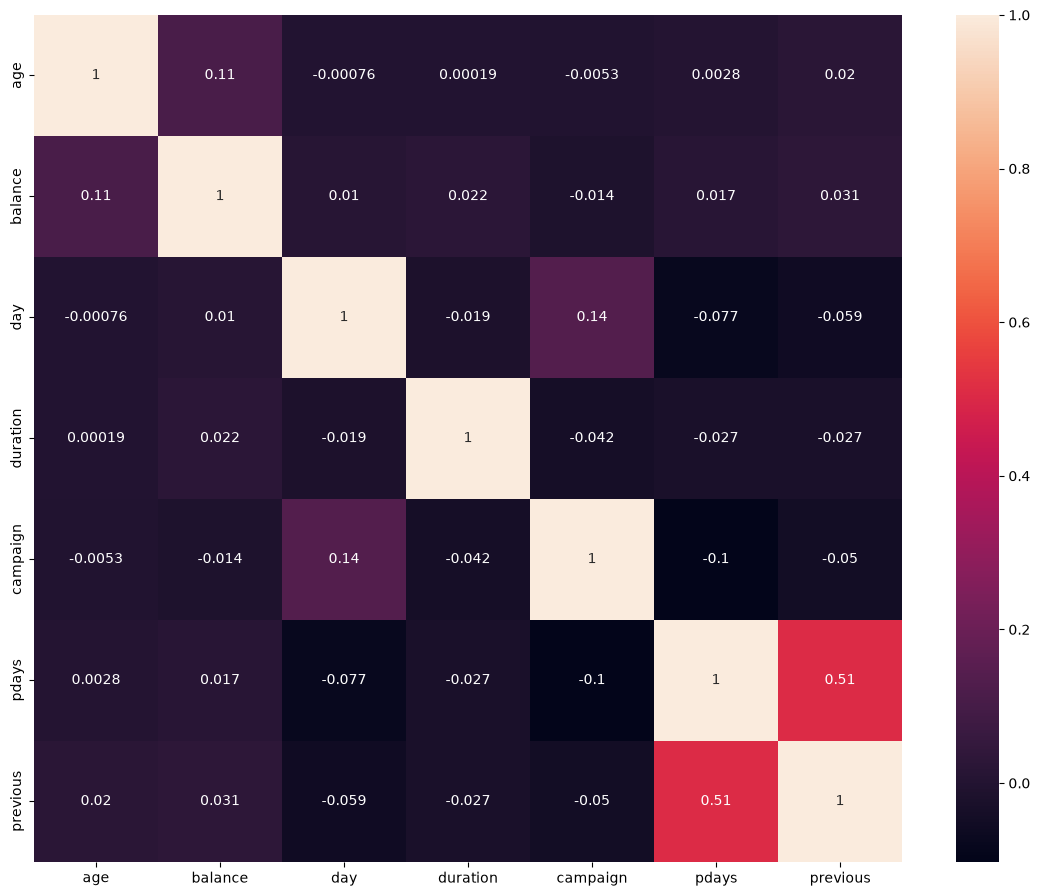

In [10]:
plt.figure(figsize=(14,11))
sns.heatmap(data=df.corr(numeric_only=True),annot=True)

In [11]:
from sklearn.preprocessing import LabelEncoder,StandardScaler
for i in cols_encoded_label:
    label_encode=LabelEncoder()
    df[i]=label_encode.fit_transform(df[i])
df=pd.get_dummies(df,columns=cols_encoded_one_hot,drop_first=True,dtype=int)


In [12]:
df.T

,0,1,2,3,4,5,6,7,8,9,...,11152,11153,11154,11155,11156,11157,11158,11159,11160,11161
age,59,56,41,55,54,42,56,60,37,28,...,34,43,52,35,34,33,39,32,43,34
default,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
balance,2343,45,1270,2476,184,0,830,545,1,5090,...,390,35,523,80,-72,1,733,29,0,0
housing,1,0,1,1,0,1,1,1,1,1,...,1,0,1,1,1,1,0,0,0,0
loan,0,0,0,0,0,1,1,0,0,0,...,0,0,1,1,0,0,0,0,1,0
day,5,5,5,5,5,5,6,6,6,6,...,15,9,8,21,7,20,16,19,8,9
duration,1042,1467,1389,579,673,562,1201,1030,608,1297,...,659,208,113,38,273,257,83,156,9,628
campaign,1,1,1,1,2,2,1,1,1,3,...,3,1,1,2,5,1,4,2,2,1
pdays,-1,-1,-1,-1,-1,-1,-1,-1,-1,-1,...,-1,-1,-1,172,-1,-1,-1,-1,172,-1
previous,0,0,0,0,0,0,0,0,0,0,...,0,0,0,2,0,0,0,0,5,0


In [13]:
X=df.drop('deposit',axis=1)
y=df['deposit'] 

In [14]:
from sklearn.model_selection import train_test_split,cross_val_score
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [15]:
sclaer=StandardScaler()
X_train[standard_sclaer_cols]=sclaer.fit_transform(X_train[standard_sclaer_cols])
X_test[standard_sclaer_cols]=sclaer.fit_transform(X_test[standard_sclaer_cols])

In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

In [17]:
model_logistic=LogisticRegression()
model_svm=SVC(kernel='rbf')
model_tree=DecisionTreeClassifier()
model_naive=GaussianNB()
model_knn=KNeighborsClassifier()

In [18]:
scores_logistic = cross_val_score(model_logistic,X_train,y_train,cv=5,scoring='accuracy')
scores_svm = cross_val_score(model_svm,X_train,y_train,cv=5,scoring='accuracy')
scores_tree = cross_val_score(model_tree,X_train,y_train,cv=5,scoring='accuracy')
scores_naive = cross_val_score(model_naive,X_train,y_train,cv=5,scoring='accuracy')
scores_knn = cross_val_score(model_knn,X_train,y_train,cv=5,scoring='accuracy')

In [19]:
print('cross val score of logistic',scores_logistic.mean())
print('cross val score of svm',scores_svm.mean())
print('cross val score of tree',scores_tree.mean())
print('cross val score of naive',scores_naive.mean())
print('cross val score of knn',scores_knn.mean())

cross val score of logistic 0.8265196784200801
cross val score of svm 0.8526151423615358
cross val score of tree 0.7886662212477376
cross val score of naive 0.7085904372947388
cross val score of knn 0.8136404841891964


### scores_svm>scores_logistic>scores_tree>scores_naive

## Now we will work on cv

In [ ]:
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV

In [21]:
#grid search cv on knn model 
grid_classifier_knn=GridSearchCV((model_knn),{
    'n_neighbors':[1,3,5,8,11,15,19],
    'weights':['uniform','distance'],
    'algorithm':['auto', 'ball_tree', 'kd_tree', 'brute'],
    'metric':['euclidean','manhattan']
},cv=5,return_train_score=False)

In [22]:
grid_classifier_knn.fit(X_train,y_train)
grid_classifier_knn.best_score_,grid_classifier_knn.best_params_

(np.float64(0.8193516958855211),
 {'algorithm': 'auto',
  'metric': 'euclidean',
  'n_neighbors': 15,
  'weights': 'distance'})

In [23]:
##svm grid search modle
'''grid_classifier_svm = GridSearchCV((model_svm),{
    'kernel':['linear', 'rbf', 'sigmoid'],
    'C':[0.1,1,3,10,18,35],
    'gamma':['auto', "scale"]
},cv=5,return_train_score=False)
grid_classifier_svm.fit(X,y)
grid_classifier_svm.best_score_,grid_classifier_svm.best_params_'''

'grid_classifier_svm = GridSearchCV((model_svm),{\n    \'kernel\':[\'linear\', \'rbf\', \'sigmoid\'],\n    \'C\':[0.1,1,3,10,18,35],\n    \'gamma\':[\'auto\', "scale"]\n},cv=5,return_train_score=False)\ngrid_classifier_svm.fit(X,y)\ngrid_classifier_svm.best_score_,grid_classifier_svm.best_params_'

In [37]:
##grid search on decision tree
grid_classifier_tree=GridSearchCV((model_tree),{
    'criterion':['gini','entropy','log_loss'],
    'max_depth':[5, 10, 15, 20],
    'min_samples_split':[2, 5, 10, 20],
    'min_samples_leaf':[1, 2, 5, 10]
},cv=5,return_train_score=False)
grid_classifier_tree.fit(X_train,y_train)
grid_classifier_tree.best_score_,grid_classifier_tree.best_params_

(np.float64(0.8239449060699308),
 {'criterion': 'gini',
  'max_depth': 10,
  'min_samples_leaf': 1,
  'min_samples_split': 20})

## Ensemble techniques

#### Bagging

In [38]:
##Random Forest
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier,GradientBoostingClassifier,StackingClassifier

In [ ]:
model_forest= RandomForestClassifier()
grid_search_forest=RandomizedSearchCV(model_forest,{
    'n_estimators':[4,10,18,25,31,40],
    'max_depth':[2,5,8,10,12],
    'min_samples_split':[2,5,10,20],
    'min_samples_leaf':[1, 2, 5, 10]
},n_iter=5,cv=5,return_train_score=False)
grid_search_forest.fit(X_train,y_train)
grid_search_forest.best_params_,grid_search_forest.best_score_ 

({'n_estimators': 25,
  'min_samples_split': 2,
  'min_samples_leaf': 2,
  'max_depth': 8},
 np.float64(0.8382807456689282))

In [33]:
from sklearn.metrics import *
model_forest2= RandomForestClassifier(n_estimators=25,min_samples_split=2,min_samples_leaf=2,max_depth=8)
model_forest.fit(X_train,y_train)
y_pred_forest = model_forest.predict(X_test)


In [36]:
print(accuracy_score(y_pred_forest,y_test))
print(classification_report(y_pred_forest,y_test))
print(confusion_matrix(y_pred_forest,y_test))

0.8378862516793552
              precision    recall  f1-score   support

           0       0.82      0.86      0.84      1102
           1       0.86      0.81      0.84      1131

    accuracy                           0.84      2233
   macro avg       0.84      0.84      0.84      2233
weighted avg       0.84      0.84      0.84      2233

[[953 149]
 [213 918]]


### stacking

In [40]:
estimators=[('knn',KNeighborsClassifier(algorithm='auto',metric='euclidean',n_neighbors= 15,weights= 'distance')),
            ('lr',LogisticRegression()),
            ('dt',DecisionTreeClassifier(criterion= 'gini',max_depth= 10,min_samples_leaf= 1,min_samples_split= 20)),
            ('naive',GaussianNB())]
meta_learner = SVC(kernel='rbf',gamma='scale')
stacking=StackingClassifier(estimators=estimators,final_estimator=meta_learner)
stacking.fit(X_train,y_train)
y_pred_stacking = stacking.predict(X_test)

In [42]:
print(accuracy_score(y_pred_stacking,y_test))
print(classification_report(y_pred_stacking,y_test))
print(confusion_matrix(y_pred_stacking,y_test))

0.8392297357814599
              precision    recall  f1-score   support

           0       0.81      0.88      0.84      1073
           1       0.88      0.81      0.84      1160

    accuracy                           0.84      2233
   macro avg       0.84      0.84      0.84      2233
weighted avg       0.84      0.84      0.84      2233

[[940 133]
 [226 934]]


## Boosting

### Adaboost

In [47]:
ada_model=AdaBoostClassifier()
grid_search_ada=GridSearchCV( ada_model,{
    'n_estimators':[4,10,18,25,31,40,50,60],
    'learning_rate':[0.1,1,3,5,8]
},cv=5,return_train_score=False)
grid_search_ada.fit(X_train,y_train)
grid_search_ada.best_params_,grid_search_ada.best_score_ 

({'learning_rate': 1, 'n_estimators': 60}, np.float64(0.808713021602818))

In [49]:
ada_model2=AdaBoostClassifier(n_estimators= 60,learning_rate=1)
ada_model2.fit(X_train,y_train)
y_pred_ada=ada_model2.predict(X_test)
print(accuracy_score(y_pred_ada,y_test))
print(classification_report(y_pred_ada,y_test))
print(confusion_matrix(y_pred_ada,y_test))

0.8042991491267353
              precision    recall  f1-score   support

           0       0.82      0.81      0.81      1193
           1       0.78      0.80      0.79      1040

    accuracy                           0.80      2233
   macro avg       0.80      0.80      0.80      2233
weighted avg       0.80      0.80      0.80      2233

[[961 232]
 [205 835]]


### gradient boost

In [56]:
gradient_model=GradientBoostingClassifier()
grid_search_gradient=RandomizedSearchCV( gradient_model,{
    'n_estimators':[4,10,18,25,31,40,50,60,100],
    'learning_rate':[0.1,1,3,5,8],
    'loss' :['log_loss', 'exponential'],
    'min_samples_split': [2,4,8,12,18],
    'min_samples_leaf': [2,4,8,10,15,20,25],
    'max_depth': [3,6,9,14,18,22],
    'max_features': [ 'sqrt', 'log2']
},n_iter=5,cv=5,return_train_score=False, scoring="f1",n_jobs=1,error_score="raise")
grid_search_gradient.fit(X_train,y_train)
grid_search_gradient.best_params_,grid_search_gradient.best_score_

({'n_estimators': 31,
  'min_samples_split': 2,
  'min_samples_leaf': 20,
  'max_features': 'sqrt',
  'max_depth': 9,
  'loss': 'exponential',
  'learning_rate': 0.1},
 np.float64(0.8448569719404523))

In [58]:
gradient_model2=GradientBoostingClassifier(n_estimators= 31,min_samples_split= 2,min_samples_leaf= 20,max_features= 'sqrt',max_depth= 9,loss= 'exponential',learning_rate= 0.1)
gradient_model2.fit(X_train,y_train)
y_pred_gradient=gradient_model2.predict(X_test)
print(accuracy_score(y_pred_gradient,y_test))
print(classification_report(y_pred_gradient,y_test))
print(confusion_matrix(y_pred_gradient,y_test))

0.8311688311688312
              precision    recall  f1-score   support

           0       0.82      0.85      0.84      1125
           1       0.84      0.81      0.83      1108

    accuracy                           0.83      2233
   macro avg       0.83      0.83      0.83      2233
weighted avg       0.83      0.83      0.83      2233

[[957 168]
 [209 899]]


### XGboost

In [59]:
import xgboost as xgb
from xgboost import XGBClassifier

In [60]:
xgb_model=XGBClassifier()
xgb_model.fit(X_train,y_train)
y_pred_xgb=xgb_model.predict(X_test)
print(accuracy_score(y_pred_xgb,y_test))
print(classification_report(y_pred_xgb,y_test))
print(confusion_matrix(y_pred_xgb,y_test))


0.83833407971339
              precision    recall  f1-score   support

           0       0.83      0.86      0.84      1119
           1       0.85      0.82      0.83      1114

    accuracy                           0.84      2233
   macro avg       0.84      0.84      0.84      2233
weighted avg       0.84      0.84      0.84      2233

[[962 157]
 [204 910]]
